# 05. Retrieval Engineering
## Dense → BM25 → Hybrid → RRF

### 이번 실습의 위치

```text
01 Naive RAG
    ↓
02 Document Processing
    ↓
03 Query Rewriting
    ↓
04 Multi Query
    ↓
05 Retrieval Engineering
   Dense + BM25 + RRF
    ↓
06 Reranking
```

이번 실습의 목적은 **검색기 자체를 개선하는 방법**을 이해하는 것이다.

### 학습 목표

실습 후 다음 네 가지를 설명할 수 있으면 충분하다.

1. Dense Retrieval과 BM25의 차이
2. Hybrid Retrieval이 필요한 이유
3. 서로 다른 검색 점수를 직접 합치기 어려운 이유
4. RRF가 검색 결과의 **순위(rank)** 를 결합하는 방법

> 핵심: **Dense는 의미를 찾고, BM25는 정확한 단어를 찾으며, RRF는 두 검색 결과의 순위를 결합한다.**


# 1. 환경 설정

02번 실습에서 만든 ChromaDB를 그대로 사용한다.

Dense와 BM25를 공정하게 비교하기 위해 **동일한 chunk corpus**를 사용한다.

필요 패키지:

```bash
uv add langchain-chroma rank-bm25
```


In [ ]:
# [환경 설정] 02번 ChromaDB(Dense용)와 같은 chunk 목록을 BM25에도 써서 공정하게 비교한다
import sys
import re
from pathlib import Path

from langchain_chroma import Chroma  # Dense 검색용 벡터DB 연결
from langchain_core.documents import Document  # 검색 결과를 담는 LangChain 문서 객체
from rank_bm25 import BM25Okapi  # 키워드 기반(BM25) 검색기

sys.path.append("..")  # 상위 폴더의 common_config.py를 import하기 위한 경로 추가
from common_config import embedding_model

DB_PATH = Path("chroma_db/ai_trend_report_doc_chunks")  # 02번에서 저장한 DB 위치
COLLECTION_NAME = "ai_trend_report_2026_doc_chunks"

if not DB_PATH.exists():  # DB가 없으면 검색할 corpus 자체가 없으므로 중단
    raise FileNotFoundError(
        "02_document_processing_ai_trend.ipynb를 먼저 실행하세요."
    )

embeddings = embedding_model()  # Dense에서 질문/chunk를 벡터로 바꾸는 임베딩 모델

# 새로 만들지 않고 기존 컬렉션에 연결만 한다
vector_store = Chroma(
    collection_name=COLLECTION_NAME,
    embedding_function=embeddings,
    persist_directory=str(DB_PATH),
)

print("저장된 chunk 수:", vector_store._collection.count())


# 2. Dense Retrieval

Dense Retrieval은 Query와 Document를 embedding vector로 변환한 뒤,
벡터 공간에서 가까운 문서를 찾는 **의미 기반 검색(Semantic Search)** 이다.

```text
Query
  ↓
Embedding
  ↓
Vector Search
  ↓
Top-k Documents
```

### 특징

- 표현이 달라도 의미가 비슷하면 찾을 수 있다.
- 자연어 질문에 강하다.
- 정확한 정책명·제품명·전문용어 검색에서는 놓치는 문서가 생길 수 있다.


In [ ]:
# [Dense] 질문을 임베딩으로 바꾼 뒤 벡터 거리가 가까운 chunk k개를 찾는다
# 임베딩 변환은 vector_store 안에서 자동으로 일어난다 (embedding_function 덕분)
def dense_search(query, k=5):
    return vector_store.similarity_search(query, k=k)


# 3. BM25 Retrieval

BM25는 embedding을 사용하지 않고 Query의 단어와 문서의 단어가 얼마나 잘 일치하는지를 계산하는
**키워드 기반 검색(Lexical Search)** 이다.

```text
Query Terms
    ↓
Keyword Matching
    ↓
BM25 Score
    ↓
Top-k Documents
```

### Dense와 BM25의 차이

| 방법 | 검색 기준 | 강점 |
|---|---|---|
| Dense | 의미(Semantic) | 자연어 질문, 의미가 비슷한 표현 |
| BM25 | 단어(Lexical) | 정책명, 전문용어, 고유명사 |

예: `AI 기본법`, `EU AI Act`, `One-Source Multi-Use`


In [ ]:
# [BM25 준비 1] Chroma에 저장된 chunk 본문과 metadata를 전부 꺼낸다
# → Dense와 BM25가 "같은 문서 집합"을 보도록 맞추는 것이 핵심
stored = vector_store.get(
    include=["documents", "metadatas"]
)

# [BM25 준비 2] 꺼낸 데이터를 LangChain Document 목록으로 재구성한다
corpus_docs = []

for text, metadata in zip(
    stored["documents"],
    stored["metadatas"],
):
    doc = Document(
        page_content=text,
        metadata=metadata or {},  # metadata가 None이면 빈 dict로 대체 (에러 방지)
    )
    corpus_docs.append(doc)


# [BM25 준비 3] 토큰화: 소문자 변환 후 \w+ 패턴으로 단어만 추출
# 공백/구두점은 제거되고, "AI", "ai"는 같은 토큰으로 취급된다
def tokenize(text):
    return re.findall(r"\w+", text.lower())


# [BM25 준비 4] 모든 chunk를 토큰 리스트로 바꾼다 (BM25의 입력 형식)
tokenized_corpus = []

for doc in corpus_docs:
    tokens = tokenize(doc.page_content)
    tokenized_corpus.append(tokens)


# [BM25 준비 5] 토큰화된 corpus로 BM25 인덱스를 만든다
# 단어 빈도와 문서 길이를 기반으로 점수를 매기는 키워드 검색기
bm25 = BM25Okapi(tokenized_corpus)

print("BM25 문서 수:", len(corpus_docs))


In [ ]:
# [BM25] 질문도 corpus와 "같은 방식"으로 토큰화해야 단어가 일치할 수 있다
def bm25_search(query, k=5):
    query_tokens = tokenize(query)  # 질문을 단어 토큰 리스트로 변환

    # 질문 토큰과 단어 일치도가 높은 chunk 상위 k개를 반환 (임베딩 사용 안 함)
    return bm25.get_top_n(
        query_tokens,
        corpus_docs,
        n=k,
    )


# 4. Dense vs BM25 비교

차이를 보기 위해 질문은 **두 종류만** 사용한다.

```text
의미 중심 질문
→ Dense의 강점을 확인

정확한 용어 중심 질문
→ BM25의 강점을 확인
```

중요한 것은 어느 검색기가 항상 더 좋다고 결론내리는 것이 아니다.

> **질문의 성격에 따라 Dense와 BM25가 서로 다른 관련 문서를 찾을 수 있다.**


In [ ]:
# [비교] 같은 질문에 Dense와 BM25 결과를 나란히 출력해 차이를 본다
def print_results(title, docs):
    print(f"\n[{title}]")

    for rank, doc in enumerate(docs, start=1):  # 순위는 1위부터
        print(
            f"{rank}. "
            f"chunk={doc.metadata.get('chunk_id')} "
            f"| pages={doc.metadata.get('pages')}"
        )


# 질문 1: 의미 중심 → Dense가 유리할 것으로 예상
# (정확한 단어가 본문에 없어도 "업무 활용" 같은 의미가 비슷하면 찾을 수 있음)
query1 = "기업 내부에서 AI가 업무에 어떻게 활용될 것으로 전망되나요?"

dense_docs = dense_search(query1, k=3)
bm25_docs = bm25_search(query1, k=3)

print("\nQUERY:", query1)
print_results("Dense", dense_docs)
print_results("BM25", bm25_docs)


# 질문 2: 정확한 용어 중심 → BM25가 유리할 것으로 예상
# ("One-Source Multi-Use"라는 단어가 본문에 그대로 있으면 키워드로 바로 잡힘)
query2 = "One-Source Multi-Use는 어떤 맥락에서 제시되었나요?"

dense_docs = dense_search(query2, k=3)
bm25_docs = bm25_search(query2, k=3)

print("\nQUERY:", query2)
print_results("Dense", dense_docs)
print_results("BM25", bm25_docs)


# 5. Hybrid Retrieval

Dense와 BM25는 서로 다른 장점이 있다.

따라서 두 검색 결과를 함께 사용하면 검색 후보를 더 다양하게 확보할 수 있다.

```text
                 ┌─ Dense Retrieval
Query ───────────┤
                 └─ BM25 Retrieval
                        ↓
                  Hybrid Retrieval
```

하지만 Dense와 BM25의 **점수 척도는 서로 다르다.**

```text
Dense distance : 0.18, 0.25, 0.31 ...
BM25 score     : 12.4, 8.7, 5.1 ...
```

따라서 두 점수를 그대로 더하거나 평균내는 방식은 적절하지 않다.

이 문제를 간단하게 해결하는 방법 중 하나가 **RRF(Reciprocal Rank Fusion)** 이다.


# 6. RRF — Reciprocal Rank Fusion

RRF는 검색기의 원래 점수를 합치는 것이 아니라 **검색 결과의 순위(rank)** 를 결합한다.

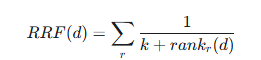
| 기호 | 의미 |
|---|---|
| \(RRF(d)\) | 문서 \(d\)의 최종 RRF 점수 |
| \(\sum\) | **합한다(Summation)**는 의미 |
| \(r\) | 각각의 검색기(Retriever) |
| \(k\) | 순위 영향력을 조절하는 상수, 보통 60 사용 |
| \(rank_r(d)\) | 검색기 \(r\)에서 문서 \(d\)의 순위 |
| \(d\) | 검색된 문서(Document) |

```text
Dense Ranking          BM25 Ranking

D3 → 1위              D1 → 1위
D7 → 2위              D4 → 2위
D1 → 3위              D3 → 3위
       \                 /
        \               /
          ---- RRF ----
               ↓
          Hybrid Ranking
```

즉,

```text
Score Fusion  X
Rank Fusion   O
```

두 검색기에서 반복적으로 상위에 등장하는 문서는 최종 순위에서도 높은 점수를 얻기 쉽다.


In [ ]:
# [RRF] 두 검색 결과의 "순위"만 사용해 하나의 순위로 합친다
# 점수(0.18 거리, 12.4 BM25 점수)는 척도가 달라서 직접 더할 수 없기 때문
def rrf(dense_docs, bm25_docs, k=60):
    scores = {}     # chunk_id별 누적 RRF 점수
    documents = {}  # chunk_id → Document (최종 반환용)

    for result in [dense_docs, bm25_docs]:  # 검색기 두 개를 차례로 처리
        for rank, doc in enumerate(result, start=1):  # rank는 1위부터
            chunk_id = doc.metadata["chunk_id"]

            if chunk_id not in scores:
                scores[chunk_id] = 0
                documents[chunk_id] = doc

            # 공식: score += 1 / (k + rank)
            # 순위가 높을수록(rank 작을수록) 점수가 크고, k=60은 상위권 쏠림을 완화하는 완충값
            # 두 검색기에서 모두 나온 문서는 점수가 두 번 더해져 자연스럽게 위로 올라간다
            scores[chunk_id] += 1 / (k + rank)

    # 누적 점수가 높은 순으로 정렬
    ranked_ids = sorted(
        scores,
        key=scores.get,
        reverse=True,
    )

    return [documents[chunk_id] for chunk_id in ranked_ids]


# 7. 최종 비교

이제 같은 Query에 대해 세 검색 결과의 **순위만** 비교한다.

```text
Dense
   vs
BM25
   vs
Hybrid + RRF
```

비교할 것은 네 가지이다.

1. Dense가 찾은 상위 문서는 무엇인가?
2. BM25가 찾은 상위 문서는 무엇인가?
3. 두 검색 결과가 서로 다른가?
4. RRF를 적용한 Hybrid 결과에는 어떤 문서가 올라왔는가?


In [ ]:
# [최종 비교] "AI 기본법 시행령" 같은 정확한 용어 + 의미 질문이 섞인 경우
query = "AI 기본법 시행령과 글로벌 규제 정합성은 어떻게 설명되나요?"

# 1. Dense 후보 8개 (의미 기반)
dense_docs = dense_search(query, k=8)

# 2. BM25 후보 8개 (키워드 기반) → 두 검색기가 서로 다른 후보를 가져올 수 있음
bm25_docs = bm25_search(query, k=8)

# 3. 두 순위를 RRF로 결합 (후보 16개 → 하나의 순위)
hybrid_docs = rrf(
    dense_docs,
    bm25_docs,
    k=60,
)

# 4. 최종 답변에 쓸 상위 5개만 사용
hybrid_docs = hybrid_docs[:5]


print("QUERY:", query)

# 세 방식의 순위를 나란히 보여줘서 Hybrid가 무엇을 바꿨는지 확인
print_results("Dense", dense_docs[:5])
print_results("BM25", bm25_docs[:5])
print_results("Hybrid + RRF", hybrid_docs)


# 8. 핵심 정리와 다음 단계

## 오늘 기억할 것

```text
Dense
→ Semantic Search
→ 의미가 비슷한 문서를 찾는다.

BM25
→ Lexical Search
→ 정확한 단어가 포함된 문서를 찾는다.

Hybrid
→ Dense + BM25
→ 서로 다른 검색 방식의 장점을 함께 사용한다.

RRF
→ Rank Fusion
→ 서로 다른 검색 결과의 순위를 결합한다.
```

## 주의할 점

1. Hybrid가 항상 Dense보다 좋은 것은 아니다.
2. BM25는 tokenizer 품질의 영향을 받는다.
3. RRF는 문서 내용을 다시 판단하는 모델이 아니라 **검색 결과의 순위를 결합하는 방법**이다.

그래서 다음 단계에서 **Reranking**이 필요하다.

```text
Dense + BM25
      ↓
Hybrid Retrieval
      ↓
RRF
      ↓
Candidate Top-N
      ↓
06. Reranking
      ↓
Final Top-k
```

> 05번의 핵심은 **검색 후보를 더 잘 확보하는 것**, 06번의 핵심은 **확보한 후보의 관련성을 다시 평가하는 것**이다.
